<a href="https://colab.research.google.com/github/angieapol33-bot/FUNDAI-Final-Insurance-Premium-Calculator-10/blob/main/Insurance_Premium_Calculator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏥 FUNDAI Final Project — Insurance Premium Calculator (Health)

**Course:** Fundamentals of Artificial Intelligence (FUNDAI)  
**Topic 10:** Insurance Premium Calculator (Health or Auto)  
**AI Technique:** Tabular Regression  
**Dataset:** Medical Cost Personal Dataset (Kaggle)

**Group Members:**  
- Member 1 — Data / Preprocessing / EDA  
- Member 2 — Modeling / Hyperparameter Tuning / Evaluation  
- Member 3 — Gradio Deployment / Ethics / Documentation  

> **Instructions:** Runtime → Restart and run all.  
> At the end, a Gradio demo will launch (public share link available in Colab).


## 1. Install packages & Imports


In [13]:
!pip install -q gradio joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib
import warnings
warnings.filterwarnings("ignore")

print("✅ Libraries imported successfully")


✅ Libraries imported successfully


## 2. Load Dataset

We use the classic **Medical Cost Personal Dataset** (1,338 records).  
Public mirror of the Kaggle dataset by mirichoi0218.


In [14]:
DATA_URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(DATA_URL)

print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nInfo:")
df.info()

print("\nDescriptive statistics:")
display(df.describe())


Shape: (1338, 7)

First 5 rows:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Descriptive statistics:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## 3. Exploratory Data Analysis (EDA)


Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Smoker distribution:
 smoker
no     1064
yes     274
Name: count, dtype: int64

Average charges by smoker status:
smoker
no      8434.27
yes    32050.23
Name: charges, dtype: float64


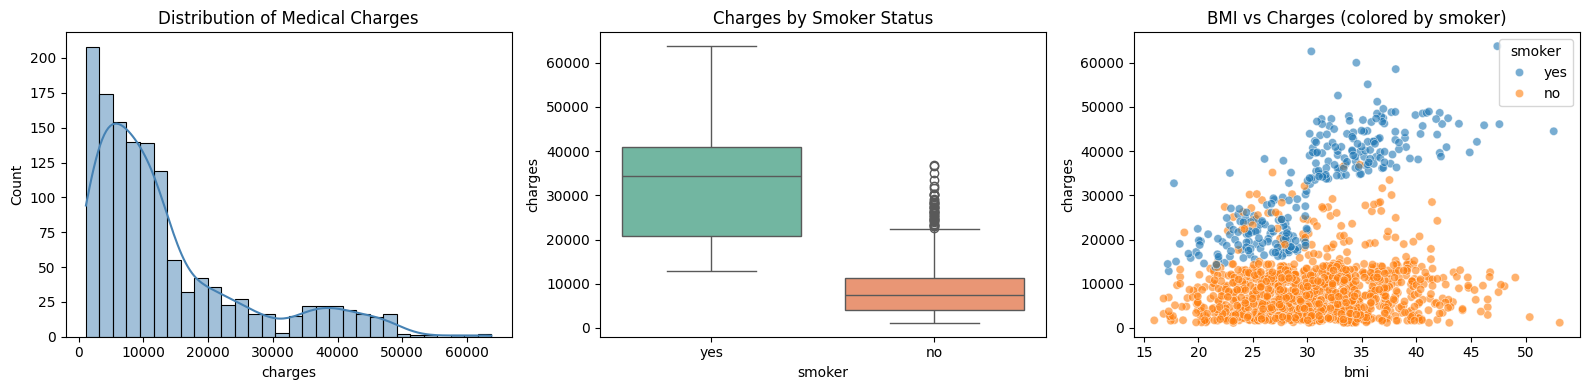

In [15]:
print("Missing values:\n", df.isnull().sum())
print("\nSmoker distribution:\n", df["smoker"].value_counts())
print("\nAverage charges by smoker status:")
print(df.groupby("smoker")["charges"].mean().round(2))


fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["charges"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Medical Charges")

sns.boxplot(x="smoker", y="charges", data=df, ax=axes[1], palette="Set2")
axes[1].set_title("Charges by Smoker Status")

sns.scatterplot(x="bmi", y="charges", hue="smoker", data=df, ax=axes[2], alpha=0.6)
axes[2].set_title("BMI vs Charges (colored by smoker)")

plt.tight_layout()
plt.show()


## 4. Preprocessing Pipeline

- Numeric features → `StandardScaler`
- Categorical features → `OneHotEncoder` (drop first to avoid dummy trap)
- 80/20 train-test split


In [16]:
X = df.drop("charges", axis=1)
y = df["charges"]

numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train size: {X_train.shape[0]}  |  Test size: {X_test.shape[0]}")


Train size: 1070  |  Test size: 268


In [17]:
def evaluate(y_true, y_pred, name="Model"):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"\n{name}")
    print(f"  MAE  : ${mae:,.2f}")
    print(f"  RMSE : ${rmse:,.2f}")
    print(f"  R²   : {r2:.4f}")
    return {"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

results = []


## 5. Baseline Model — Linear Regression


In [18]:
pipe_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)
results.append(evaluate(y_test, y_pred_lr, "Linear Regression (Baseline)"))



Linear Regression (Baseline)
  MAE  : $4,181.19
  RMSE : $5,796.28
  R²   : 0.7836


## 6. Random Forest + Hyperparameter Tuning

We use `GridSearchCV` (3-fold CV) to find good hyperparameters.


In [19]:
pipe_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42, n_jobs=-1))
])

param_grid = {
    "regressor__n_estimators": [100, 200],
    "regressor__max_depth": [None, 10, 20],
    "regressor__min_samples_split": [2, 5]
}

print("Running GridSearchCV (may take 1-2 minutes)...")
grid_rf = GridSearchCV(
    pipe_rf, param_grid, cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1, verbose=1
)
grid_rf.fit(X_train, y_train)

print("\nBest parameters:", grid_rf.best_params_)
best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test)
results.append(evaluate(y_test, y_pred_rf, "Random Forest (Tuned)"))


Running GridSearchCV (may take 1-2 minutes)...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best parameters: {'regressor__max_depth': 10, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 200}

Random Forest (Tuned)
  MAE  : $2,533.65
  RMSE : $4,499.91
  R²   : 0.8696


## 7. MLP Regressor (Neural Network)

This ties directly to the ANN / Multi-Layer Perceptron topic of the course.


In [20]:
pipe_mlp = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=500,
        random_state=42,
        early_stopping=True,
        validation_fraction=0.1
    ))
])

print("Training MLP Regressor...")
pipe_mlp.fit(X_train, y_train)
y_pred_mlp = pipe_mlp.predict(X_test)
results.append(evaluate(y_test, y_pred_mlp, "MLP Regressor (64-32)"))


Training MLP Regressor...

MLP Regressor (64-32)
  MAE  : $5,683.79
  RMSE : $7,347.22
  R²   : 0.6523


## 8. Model Comparison


In [21]:
results_df = pd.DataFrame(results)
print("=== Model Comparison Table ===")
display(results_df.style.format({
    "MAE": "${:,.2f}",
    "RMSE": "${:,.2f}",
    "R2": "{:.4f}"
}).highlight_max(subset=["R2"], color="#c6f6d5").highlight_min(subset=["MAE", "RMSE"], color="#c6f6d5"))


best_model = best_rf
joblib.dump(best_model, "insurance_premium_model.joblib")
print("\n✅ Best model saved as 'insurance_premium_model.joblib'")


=== Model Comparison Table ===


,Model,MAE,RMSE,R2
0,Linear Regression (Baseline),"$4,181.19","$5,796.28",0.7836
1,Random Forest (Tuned),"$2,533.65","$4,499.91",0.8696
2,MLP Regressor (64-32),"$5,683.79","$7,347.22",0.6523



✅ Best model saved as 'insurance_premium_model.joblib'


## 9. Feature Importance (Random Forest)


,feature,importance
4,smoker_yes,0.633805
1,bmi,0.206359
0,age,0.131168
2,children,0.015396
5,region_northwest,0.003857
6,region_southeast,0.003399
3,sex_male,0.003294
7,region_southwest,0.002722


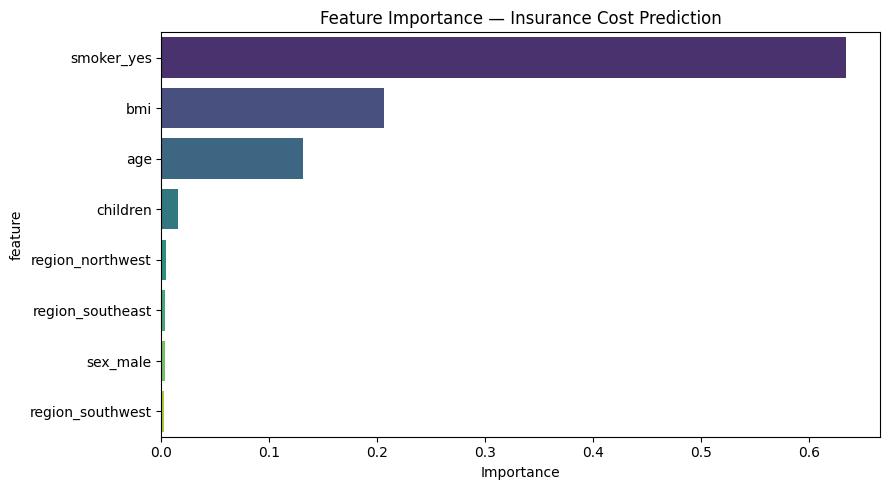

In [22]:
# Recover feature names after one-hot encoding
ohe = best_model.named_steps["preprocessor"].named_transformers_["cat"]
cat_names = list(ohe.get_feature_names_out(categorical_features))
feature_names = numeric_features + cat_names

importances = best_model.named_steps["regressor"].feature_importances_
imp_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

display(imp_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=imp_df, x="importance", y="feature", palette="viridis")
plt.title("Feature Importance — Insurance Cost Prediction")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## 10. Prediction Helper Function


In [23]:
def predict_premium(age, sex, bmi, children, smoker, region):
    """Return monthly estimate, annual charges, and risk category."""
    input_df = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "bmi": bmi,
        "children": children,
        "smoker": smoker,
        "region": region
    }])
    annual = float(best_model.predict(input_df)[0])
    monthly = annual / 12.0

    if annual < 5000:
        risk = "🟢 Low Risk"
    elif annual < 15000:
        risk = "🟠 Moderate Risk"
    else:
        risk = "🔴 High Risk"

    return f"${monthly:,.2f}", f"${annual:,.2f}", risk


print("Sample prediction (30-year-old non-smoker male, BMI 25):")
print(predict_premium(30, "male", 25.0, 1, "no", "northeast"))


Sample prediction (30-year-old non-smoker male, BMI 25):
('$676.58', '$8,118.98', '🟠 Moderate Risk')


## 11. Gradio Interactive Demo

Run the cell below. In Colab you will get a public shareable link.


In [24]:
import gradio as gr

demo = gr.Interface(
    fn=predict_premium,
    inputs=[
        gr.Slider(18, 64, value=30, step=1, label="Age"),
        gr.Radio(["male", "female"], label="Sex", value="male"),
        gr.Slider(15.0, 53.0, value=25.0, step=0.1, label="BMI (Body Mass Index)"),
        gr.Slider(0, 5, value=0, step=1, label="Number of Children / Dependents"),
        gr.Radio(["yes", "no"], label="Smoker", value="no"),
        gr.Dropdown(
            ["northeast", "northwest", "southeast", "southwest"],
            label="Region", value="northeast"
        )
    ],
    outputs=[
        gr.Textbox(label="Estimated Monthly Premium"),
        gr.Textbox(label="Estimated Annual Medical Charges"),
        gr.Textbox(label="Risk Category")
    ],
    title="🏥 Insurance Premium Calculator (Health)",
    description=(
        "Educational Gradio demo for FUNDAI Final Project.\n\n"
        "Predicts medical insurance cost using a Random Forest tabular regression model "
        "trained on the public Medical Cost Personal Dataset.\n\n"
        "**Disclaimer:** This is an educational tool only. Real insurance pricing involves "
        "many additional factors and is subject to regulation."
    ),
    examples=[
        [19, "female", 27.9, 0, "yes", "southwest"],
        [45, "male", 28.5, 2, "no", "northeast"],
        [60, "female", 32.0, 0, "yes", "southeast"],
        [25, "male", 22.0, 0, "no", "northwest"]
    ],
    theme=gr.themes.Soft()
)


demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://62ee64cffa49d6c17b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 12. Ethics & Bias Notes (summary)

See the full analysis in **Technical_Documentation.pdf**.

Key points required by the topic brief:

1. **Penalizing lifestyle/health choices**  
   Smoking and high BMI dominate predictions. While actuarially relevant, heavy reliance on these features can punish individuals for behaviors influenced by addiction, socioeconomic status, or limited access to healthy options.

2. **Genetic discrimination proxies**  
   BMI can act as a weak proxy for genetic predispositions. In jurisdictions with genetic nondiscrimination laws (e.g., GINA in the US), indirect use of correlated features raises compliance questions.

3. **Fairness in risk pooling**  
   Highly individualized pricing erodes the solidarity principle of insurance. Regulators often limit the features that may be used for rating.

**Mitigations in this project:**  
- Clear educational disclaimer on the Gradio interface  
- Feature importance transparency  
- Coarse risk bands instead of only a precise continuous number  
- Full ethics section in the accompanying PDF
